In [1]:

!pip install pandas scikit-learn matplotlib


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import time
from datetime import datetime
from sklearn.ensemble import IsolationForest

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

import os

os.makedirs("logs", exist_ok=True)

log_file = "logs/application.log"

with open(log_file, "w") as file:
    file.write("Timestamp,Level,Message,Response_Time\n")

print("Log file created successfully!")


Log file created successfully!


In [4]:

import random
import time
from datetime import datetime

def generate_log():
    levels = ["INFO", "INFO", "INFO", "WARNING", "ERROR"]

    messages = {
        "INFO": ["User login successful", "Page loaded successfully"],
        "WARNING": ["High response time", "Multiple login attempts"],
        "ERROR": ["Database connection failed", "Server error"]
    }

    level = random.choice(levels)
    message = random.choice(messages[level])
    response_time = random.randint(100, 2000)

    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    log = f"{timestamp},{level},{message},{response_time}"

    with open(log_file, "a") as file:
        file.write(log + "\n")

    print(log)

print("Real-Time Log Generator Started!")

for i in range(10):
    generate_log()
    time.sleep(1)


Real-Time Log Generator Started!
2026-10-31 13:42:40,ERROR,Database connection failed,1218
2026-10-31 13:42:41,INFO,User login successful,1863
2026-10-31 13:42:42,INFO,Page loaded successfully,1307
2026-10-31 13:42:43,INFO,Page loaded successfully,858
2026-10-31 13:42:44,WARNING,High response time,1853
2026-10-31 13:42:45,INFO,User login successful,1234
2026-10-31 13:42:46,INFO,Page loaded successfully,343
2026-10-31 13:42:47,INFO,Page loaded successfully,363
2026-10-31 13:42:48,INFO,User login successful,1025
2026-10-31 13:42:49,INFO,User login successful,1797


In [5]:

# Read the log file
df = pd.read_csv(log_file)

# Display all logs
print("REAL-TIME LOG MONITORING")
print("------------------------")

display(df)

# Count log levels
print("\nLOG SUMMARY")

print("Total Logs:", len(df))
print("INFO:", (df["Level"] == "INFO").sum())
print("WARNING:", (df["Level"] == "WARNING").sum())
print("ERROR:", (df["Level"] == "ERROR").sum())


REAL-TIME LOG MONITORING
------------------------


,Timestamp,Level,Message,Response_Time
0,2026-10-31 13:42:40,ERROR,Database connection failed,1218
1,2026-10-31 13:42:41,INFO,User login successful,1863
2,2026-10-31 13:42:42,INFO,Page loaded successfully,1307
3,2026-10-31 13:42:43,INFO,Page loaded successfully,858
4,2026-10-31 13:42:44,WARNING,High response time,1853
5,2026-10-31 13:42:45,INFO,User login successful,1234
6,2026-10-31 13:42:46,INFO,Page loaded successfully,343
7,2026-10-31 13:42:47,INFO,Page loaded successfully,363
8,2026-10-31 13:42:48,INFO,User login successful,1025
9,2026-10-31 13:42:49,INFO,User login successful,1797



LOG SUMMARY
Total Logs: 10
INFO: 8
ERROR: 1


In [6]:

# Machine Learning Anomaly Detection

from sklearn.ensemble import IsolationForest

# Select features
X = df[["Response_Time"]]

# Create model
model = IsolationForest(
    contamination=0.2,
    random_state=42
)

# Train model and predict
df["Anomaly"] = model.fit_predict(X)

# Convert predictions
df["Status"] = df["Anomaly"].map({
    1: "NORMAL",
    -1: "ANOMALY"
})

# Display results
print("ANOMALY DETECTION RESULTS")
display(df[["Level", "Message", "Response_Time", "Status"]])

# Count anomalies
print("Total Anomalies:",
      (df["Status"] == "ANOMALY").sum())

print("Normal Logs:",
      (df["Status"] == "NORMAL").sum())


ANOMALY DETECTION RESULTS


,Level,Message,Response_Time,Status
0,ERROR,Database connection failed,1218,NORMAL
1,INFO,User login successful,1863,NORMAL
2,INFO,Page loaded successfully,1307,NORMAL
3,INFO,Page loaded successfully,858,NORMAL
4,WARNING,High response time,1853,NORMAL
5,INFO,User login successful,1234,NORMAL
6,INFO,Page loaded successfully,343,ANOMALY
7,INFO,Page loaded successfully,363,ANOMALY
8,INFO,User login successful,1025,NORMAL
9,INFO,User login successful,1797,NORMAL


Total Anomalies: 2
Normal Logs: 8


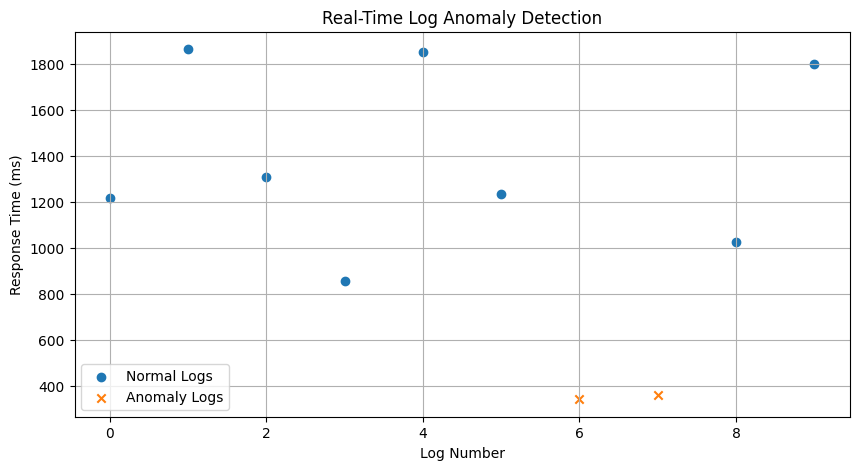

In [7]:

# Anomaly Visualization

normal = df[df["Status"] == "NORMAL"]
anomaly = df[df["Status"] == "ANOMALY"]

plt.figure(figsize=(10, 5))

plt.scatter(
    normal.index,
    normal["Response_Time"],
    label="Normal Logs",
    marker="o"
)

plt.scatter(
    anomaly.index,
    anomaly["Response_Time"],
    label="Anomaly Logs",
    marker="x"
)

plt.xlabel("Log Number")
plt.ylabel("Response Time (ms)")
plt.title("Real-Time Log Anomaly Detection")

plt.legend()
plt.grid(True)
plt.show()


In [8]:

# DevOps Log Monitoring Dashboard

total_logs = len(df)
info_count = (df["Level"] == "INFO").sum()
warning_count = (df["Level"] == "WARNING").sum()
error_count = (df["Level"] == "ERROR").sum()
anomaly_count = (df["Status"] == "ANOMALY").sum()

print("=" * 45)
print(" DEVOPS REAL-TIME LOG MONITORING DASHBOARD")
print("=" * 45)

print("Total Logs       :", total_logs)
print("INFO Logs        :", info_count)
print("WARNING Logs     :", warning_count)
print("ERROR Logs       :", error_count)
print("ANOMALY Detected :", anomaly_count)

print("=" * 45)

print("\nRECENT LOG DETAILS")
display(df.tail(10))


 DEVOPS REAL-TIME LOG MONITORING DASHBOARD
Total Logs       : 10
INFO Logs        : 8
WARNING Logs     : 1
ERROR Logs       : 1
ANOMALY Detected : 2

RECENT LOG DETAILS


,Timestamp,Level,Message,Response_Time,Anomaly,Status
0,2026-10-31 13:42:40,ERROR,Database connection failed,1218,1,NORMAL
1,2026-10-31 13:42:41,INFO,User login successful,1863,1,NORMAL
2,2026-10-31 13:42:42,INFO,Page loaded successfully,1307,1,NORMAL
3,2026-10-31 13:42:43,INFO,Page loaded successfully,858,1,NORMAL
4,2026-10-31 13:42:44,WARNING,High response time,1853,1,NORMAL
5,2026-10-31 13:42:45,INFO,User login successful,1234,1,NORMAL
6,2026-10-31 13:42:46,INFO,Page loaded successfully,343,-1,ANOMALY
7,2026-10-31 13:42:47,INFO,Page loaded successfully,363,-1,ANOMALY
8,2026-10-31 13:42:48,INFO,User login successful,1025,1,NORMAL
9,2026-10-31 13:42:49,INFO,User login successful,1797,1,NORMAL


In [9]:

# Anomaly Alert System

if anomaly_count > 0:
    print("⚠️ ALERT: ANOMALY DETECTED!")
    print("Unusual log activities found.")
else:
    print("✅ SYSTEM STATUS: NORMAL")
    print("No anomalies detected.")


⚠️ ALERT: ANOMALY DETECTED!
Unusual log activities found.


In [10]:

from IPython.display import HTML, display

total_logs = len(df)
info_count = (df["Level"] == "INFO").sum()
warning_count = (df["Level"] == "WARNING").sum()
error_count = (df["Level"] == "ERROR").sum()
anomaly_count = (df["Status"] == "ANOMALY").sum()

status = "ANOMALY DETECTED" if anomaly_count > 0 else "SYSTEM NORMAL"

dashboard = f"""
<html>
<head>
<style>
body {{
    background-color: #101827;
    color: white;
    font-family: Arial;
    padding: 20px;
}}
h1 {{
    text-align: center;
    color: #38bdf8;
}}
.container {{
    display: grid;
    grid-template-columns: repeat(3, 1fr);
    gap: 15px;
}}
.card {{
    background: #1e293b;
    padding: 25px;
    border-radius: 12px;
    text-align: center;
}}
.number {{
    font-size: 30px;
    color: #38bdf8;
    font-weight: bold;
}}
.alert {{
    background: #7f1d1d;
    padding: 18px;
    text-align: center;
    border-radius: 10px;
    margin-top: 20px;
}}
table {{
    width: 100%;
    margin-top: 20px;
    border-collapse: collapse;
    background: #1e293b;
}}
th, td {{
    padding: 12px;
    border: 1px solid #475569;
    text-align: center;
}}
th {{
    color: #38bdf8;
}}
</style>
</head>

<body>

<h1>DEVOPS LOG MONITORING DASHBOARD</h1>

<div class="container">

<div class="card">
<h3>Total Logs</h3>
<div class="number">{total_logs}</div>
</div>

<div class="card">
<h3>INFO Logs</h3>
<div class="number">{info_count}</div>
</div>

<div class="card">
<h3>WARNING Logs</h3>
<div class="number">{warning_count}</div>
</div>

<div class="card">
<h3>ERROR Logs</h3>
<div class="number">{error_count}</div>
</div>

<div class="card">
<h3>Anomalies</h3>
<div class="number">{anomaly_count}</div>
</div>

<div class="card">
<h3>System Status</h3>
<div class="number">{status}</div>
</div>

</div>

<div class="alert">
<h2>Security Monitoring Alert</h2>
<p>{status}</p>
</div>

<h2>Recent Log Records</h2>

{df.tail(10).to_html(index=False, border=0)}

</body>
</html>
"""

display(HTML(dashboard))


Timestamp,Level,Message,Response_Time,Anomaly,Status
2026-10-31 13:42:40,ERROR,Database connection failed,1218,1,NORMAL
2026-10-31 13:42:41,INFO,User login successful,1863,1,NORMAL
2026-10-31 13:42:42,INFO,Page loaded successfully,1307,1,NORMAL
2026-10-31 13:42:43,INFO,Page loaded successfully,858,1,NORMAL
2026-10-31 13:42:44,WARNING,High response time,1853,1,NORMAL
2026-10-31 13:42:45,INFO,User login successful,1234,1,NORMAL
2026-10-31 13:42:46,INFO,Page loaded successfully,343,-1,ANOMALY
2026-10-31 13:42:47,INFO,Page loaded successfully,363,-1,ANOMALY
2026-10-31 13:42:48,INFO,User login successful,1025,1,NORMAL
2026-10-31 13:42:49,INFO,User login successful,1797,1,NORMAL


In [11]:

from IPython.display import clear_output, display
import time

print("LIVE LOG MONITORING STARTED")

for i in range(10):

    generate_log()

    # Read updated log file
    df = pd.read_csv(log_file)

    # Update anomaly detection
    X = df[["Response_Time"]]
    df["Anomaly"] = model.fit_predict(X)

    df["Status"] = df["Anomaly"].map({
        1: "NORMAL",
        -1: "ANOMALY"
    })

    # Refresh dashboard
    clear_output(wait=True)

    total = len(df)
    anomalies = (df["Status"] == "ANOMALY").sum()

    print("DEVOPS LIVE LOG MONITORING")
    print("--------------------------")
    print("Total Logs:", total)
    print("Anomalies:", anomalies)

    if anomalies > 0:
        print("ALERT: ANOMALY DETECTED!")

    display(df.tail(10))

    time.sleep(2)

print("LIVE MONITORING COMPLETED")


DEVOPS LIVE LOG MONITORING
--------------------------
Total Logs: 20
Anomalies: 4
ALERT: ANOMALY DETECTED!


,Timestamp,Level,Message,Response_Time,Anomaly,Status
10,2026-10-31 13:51:28,ERROR,Server error,810,1,NORMAL
11,2026-10-31 13:51:30,ERROR,Server error,1347,1,NORMAL
12,2026-10-31 13:51:32,INFO,Page loaded successfully,426,1,NORMAL
13,2026-10-31 13:51:34,INFO,User login successful,1911,1,NORMAL
14,2026-10-31 13:51:37,ERROR,Server error,848,1,NORMAL
15,2026-10-31 13:51:39,INFO,Page loaded successfully,1874,1,NORMAL
16,2026-10-31 13:51:41,ERROR,Server error,1968,-1,ANOMALY
17,2026-10-31 13:51:43,INFO,Page loaded successfully,1696,1,NORMAL
18,2026-10-31 13:51:46,INFO,Page loaded successfully,448,-1,ANOMALY
19,2026-10-31 13:51:48,ERROR,Database connection failed,1360,1,NORMAL


LIVE MONITORING COMPLETED


In [12]:

# FINAL PROJECT TESTING

print("DEVOPS LOG MONITORING - FINAL TEST")
print("=" * 40)

print("1. Log Generation: SUCCESS")
print("2. Log Monitoring: SUCCESS")
print("3. Machine Learning: SUCCESS")
print("4. Visualization: SUCCESS")
print("5. Dashboard: SUCCESS")
print("6. Alert System: SUCCESS")

print("=" * 40)

print("TOTAL LOGS:", len(df))
print("TOTAL ANOMALIES:",
      (df["Status"] == "ANOMALY").sum())

print("\nPROJECT TESTING COMPLETED!")


DEVOPS LOG MONITORING - FINAL TEST
1. Log Generation: SUCCESS
2. Log Monitoring: SUCCESS
3. Machine Learning: SUCCESS
4. Visualization: SUCCESS
5. Dashboard: SUCCESS
6. Alert System: SUCCESS
TOTAL LOGS: 20
TOTAL ANOMALIES: 4

PROJECT TESTING COMPLETED!
